# Spark, live and visual

Day 3, before Lab 3.2. DuckDB and Polars ran every lab so far on one machine. This walkthrough shows what changes
when the work is spread over a cluster: how Spark splits it, plans it, moves data between machines, and where that
goes wrong.

Each section gives the idea, a picture drawn from what Spark just returned (step through it with **Next ▶** or
**▶ Play**), and the real Spark code on Qafila's data. 🤔 asks you to predict before you run a cell · 🔍 says what
the output means.

⚠️ Run this on **Colab**: Spark 4 needs Java 17+, and on Colab the first Spark cell installs it (about a minute).
Locally it runs on WSL, Linux or macOS with Java 17+, not on native Windows.

**Contents**
- [ ] 0 · The problem: do you need a cluster?
- [ ] 1 · Why Spark: one driver, many executors
- [ ] 2 · Partitions are tasks
- [ ] 3 · Lazy evaluation: transformations plan, actions run
- [ ] 4 · Narrow vs. wide: the shuffle
- [ ] 5 · Joins: broadcast vs. sort-merge
- [ ] 6 · Skew: one key, one huge task
- [ ] 7 · Writing: one file per task
- [ ] 8 · Summary

🎓 **Instructor notes** (instructor copy only)

- Start the first Spark cell (§1) while you introduce §0: on Colab it installs Java, about a minute.
- Open the Spark UI tab in §1 and keep it on screen; refresh it after each action.
- Core ≈ 25': §0 3' · §1 2' · §2 3' · §3 3' · §4 5' · §5 4' · §6 2' · §7 2' · §8 1'. §6 shows skew only: Lab 3.2
  does the salting.
- Lab 3.2 does pruning, broadcast timing, salting and the small-files count: don't do those here.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # tools/ and solutions/tools/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import de_utils as U
import de_viz as V
U.ensure_data()
print("data:", U.RAW, "| quick mode:", U.QUICK)

data: /mnt/c/Users/nayef/Desktop/courses/data-engineering/labs/data/raw | quick mode: False


Spark **transforms** at scale: the same work as DuckDB or Polars, spread over a cluster when one machine is not
enough.

In [2]:
V.platform_map(tool="spark")

A small data lake for Spark: DuckDB exports the raw tables to Parquet, with `orders` in daily folders
(`order_date=2026-09-23/`), as a nightly ingestion job would land them.

In [3]:
LAKE = U.lab_dir("tools_spark", reset=True)
con = U.connect(U.build_warehouse())
con.sql(f"""COPY (SELECT * EXCLUDE (_loaded_at), created_at[:10]::DATE AS order_date FROM raw.orders)
            TO '{(LAKE / "orders").as_posix()}' (FORMAT parquet, PARTITION_BY (order_date))""")
for t in ["order_items", "stores", "products"]:
    con.sql(f"""COPY (SELECT * EXCLUDE (_loaded_at) FROM raw.{t}) TO '{(LAKE / t).as_posix()}.parquet'
                (FORMAT parquet, ROW_GROUP_SIZE 20000)""")
print("order folders:", len(list((LAKE / "orders").iterdir())), "| parquet files:", U.count_files(LAKE))

order folders: 61 | parquet files: 64


## 0 · The problem: do you need a cluster?

**Scale up first; scale out when you must.** DuckDB and Polars handle hundreds of gigabytes on one large VM, with no
cluster to run. A cluster earns its cost when:
- a single job reads **terabytes**, more than one machine can scan in the time you have;
- the work must finish inside a **window** (say 01:00 to 05:00) that one machine can't meet;
- **many teams** share one platform, its data and its compute.

You will meet Spark anyway: the big cloud platforms run it, and many existing pipelines are written in it. Our data
fits on a laptop many times over; we run Spark on it to **see** how a cluster splits the work.

## 1 · Why Spark: one driver, many executors

Spark splits the data into pieces and sends the work to many machines. The **driver** plans the work, the
**executors** do it, and each executor **core** works on one piece at a time. Start Spark first (on Colab this
installs Java), then step through the picture.

In [4]:
from pyspark.sql import functions as F

spark = U.get_spark()
print("Spark", spark.version, "| master:", spark.sparkContext.master,
      "| cores:", spark.sparkContext.defaultParallelism, "| shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))
print("Spark UI:", spark.sparkContext.uiWebUrl)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/23 15:17:47 WARN Utils: Your hostname, Naif, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/23 15:17:47 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/23 15:17:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | master: local[2] | cores: 2 | shuffle partitions: 8
Spark UI: http://10.255.255.254:4040


In [5]:
V.spark_cluster(spark.sparkContext.master, spark.sparkContext.defaultParallelism)

The words you'll read in the UI and in every Spark error message:

| Word | Is |
|---|---|
| **driver** | your program: builds and optimizes the plan, schedules the tasks |
| **cluster manager** | hands out machines: YARN, Kubernetes, standalone, or a managed service |
| **executor** | a JVM process on a worker machine; runs tasks on its cores, can cache data |
| **job** | the work one **action** starts (`count`, `show`, `write`, `collect`) |
| **stage** | a run of work with no shuffle; each shuffle starts a new stage |
| **task** | one stage on one **partition**; tasks run in parallel on executor cores |

🔍 Here driver and executors share one process (`local[2]`). The code is the same on a 1,000-node cluster; only the
master changes.

The **Spark UI** shows each job's stages and tasks, with time and rows per task: it's where you debug real jobs.
Open it now and refresh it after each action below.

In [6]:
if IN_COLAB:
    from google.colab import output
    output.serve_kernel_port_as_window(4040, path="/jobs/")
else:
    print("open", spark.sparkContext.uiWebUrl, "in your browser")

open http://10.255.255.254:4040 in your browser


## 2 · Partitions are tasks

Spark splits every dataset into **partitions**. One partition processed on one core is one **task**. Input files are
cut into splits of at most `spark.sql.files.maxPartitionBytes` (128 MB by default). Our `order_items` file is only
1.5 MB, so we lower the limit to 256 KB to see several tasks on a laptop.

🤔 **Predict** · With 2 cores, how many partitions should we hope for: 1, 2, or more?

In [7]:
spark.conf.set("spark.sql.files.maxPartitionBytes", "256k")
items = spark.read.parquet((LAKE / "order_items.parquet").as_posix())
orders = spark.read.parquet((LAKE / "orders").as_posix())
products = spark.read.parquet((LAKE / "products.parquet").as_posix())
stores = spark.read.parquet((LAKE / "stores.parquet").as_posix())

parts = items.groupBy(F.spark_partition_id().alias("partition")).count().orderBy("partition").toPandas()
print("order_items partitions:", items.rdd.getNumPartitions())
parts

order_items partitions: 6


,partition,count
0,0,40960
1,1,20480
2,2,40960
3,3,20480
4,4,40960
5,5,8705


In [8]:
V.partitions(parts, cores=spark.sparkContext.defaultParallelism)

🔍 With 2 cores, two tasks run at a time; on a cluster with 400 cores, 400 do. So we want **more partitions than
cores**, so every core stays busy, but not millions of tiny ones, because each task has a fixed start-up cost. A
bigger split size gives fewer, longer tasks.

## 3 · Lazy evaluation: transformations plan, actions run

Transformations (`filter`, `withColumn`, `select`, `join`, `groupBy`) don't run anything: they add a step to a
**plan**. Only an **action** (`count`, `show`, `collect`, `write`) runs the plan as one or more **jobs**.

🤔 **Predict** · We filter, compute and select. How many Spark **jobs** does that run? And the `count()` after it?

In [9]:
jobs = lambda: len(spark.sparkContext.statusTracker().getJobIdsForGroup())   # jobs run so far in this session

before = jobs()
big_baskets = (items.filter(F.col("quantity") >= 3)
                    .withColumn("line_total", F.col("quantity") * F.col("unit_price") - F.col("discount"))
                    .select("order_id", "product_id", "quantity", "line_total"))
by_transformations = jobs() - before
n = big_baskets.count()
by_count = jobs() - before - by_transformations
print(f"jobs run by the transformations: {by_transformations} | by count(): {by_count} → {n:,} lines with 3+ units")

jobs run by the transformations: 0 | by count(): 2 → 49,371 lines with 3+ units


In [10]:
V.lazy(big_baskets,
       ['items.filter(F.col("quantity") >= 3)', '     .withColumn("line_total", …)', '     .select(…)'],
       "big_baskets.count()", by_transformations, by_count, n)

🔍 One action can become several jobs: with adaptive execution, each shuffle stage runs as its own job.

`explain()` prints the plan Spark ran. You'll read this text in Lab 3.2 and in the Spark UI's SQL tab.

In [11]:
big_baskets.explain()

== Physical Plan ==
*(1) Project [order_id#0L, product_id#2L, quantity#3L, ((cast(quantity#3L as double) * unit_price#4) - discount#5) AS line_total#47]
+- *(1) Filter (isnotnull(quantity#3L) AND (quantity#3L >= 3))
   +- *(1) ColumnarToRow
      +- FileScan parquet [order_id#0L,product_id#2L,quantity#3L,unit_price#4,discount#5] Batched: true, DataFilters: [isnotnull(quantity#3L), (quantity#3L >= 3)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/mnt/c/Users/nayef/Desktop/courses/data-engineering/labs/artifact..., PartitionFilters: [], PushedFilters: [IsNotNull(quantity), GreaterThanOrEqual(quantity,3)], ReadSchema: struct<order_id:bigint,product_id:bigint,quantity:bigint,unit_price:double,discount:double>




The same plan as a picture. Step through it **bottom-up**, the way the data flows.

In [12]:
V.plan(big_baskets)

🔍 `FileScan` has `PushedFilters: [..., GreaterThanOrEqual(quantity,3)]`: the filter reached the Parquet reader. And
there's **no `Exchange`** anywhere: `filter`, `withColumn` and `select` are **narrow**. Each partition is processed
on its own, so no data moves between tasks.

## 4 · Narrow vs. wide: the shuffle

A **narrow** step needs only the rows in its own partition. A **wide** step needs rows from other partitions, so
Spark has to **shuffle**: send every row, over the network, to the task that owns its key.

🤔 **Predict** · Purchasing wants units sold per product. Can each task answer that alone?

In [13]:
units = big_baskets.groupBy("product_id").agg(F.sum("quantity").alias("units"))
units.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[product_id#2L], functions=[sum(quantity#3L)])
   +- Exchange hashpartitioning(product_id#2L, 8), ENSURE_REQUIREMENTS, [plan_id=181]
      +- HashAggregate(keys=[product_id#2L], functions=[partial_sum(quantity#3L)])
         +- Filter (isnotnull(quantity#3L) AND (quantity#3L >= 3))
            +- FileScan parquet [product_id#2L,quantity#3L] Batched: true, DataFilters: [isnotnull(quantity#3L), (quantity#3L >= 3)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/mnt/c/Users/nayef/Desktop/courses/data-engineering/labs/artifact..., PartitionFilters: [], PushedFilters: [IsNotNull(quantity), GreaterThanOrEqual(quantity,3)], ReadSchema: struct<product_id:bigint,quantity:bigint>




In [14]:
V.plan(units)

🔍 No. Lines for one product sit in every partition, so the plan has an `Exchange hashpartitioning(product_id, 8)`.
Notice the **two** `HashAggregate` steps: `partial_sum` runs **before** the shuffle, `sum` after. The `8` is
`spark.sql.shuffle.partitions` (default 200; we set 8 for a laptop). `distinct()` is wide for the same reason, with
the same two steps around an `Exchange`.

What does a shuffle actually move? Spark sends each key to bucket `pmod(hash(key), 8)`, and `F.hash` is the same
hash function, so we can compute where every row goes:

In [15]:
moves = (big_baskets
         .select(F.spark_partition_id().alias("map_task"),
                 F.pmod(F.hash("product_id"), F.lit(8)).alias("reducer"), "product_id")
         .groupBy("map_task", "reducer", "product_id").count()
         .toPandas())
V.shuffle(moves, key="product_id", n_out=8)

Now run it. Each `Exchange` starts a new **stage**: check the Stages tab after this action. Adaptive execution may
merge the 8 small reducer partitions into fewer tasks at run time.

In [16]:
units.orderBy(F.desc("units")).show(5)

+----------+-----+
|product_id|units|
+----------+-----+
|      1177| 7971|
|      1053| 6459|
|      1309| 5721|
|      1149| 4901|
|      1009| 4275|
+----------+-----+
only showing top 5 rows


## 5 · Joins: broadcast vs. sort-merge

For a join, matching rows must meet in the same task. Either the small table is **copied** to every executor
(broadcast), or **both** tables are shuffled by the join key (sort-merge).

Each order line needs its product's category: 170k rows against 356. Spark estimates `products` is tiny, so it
broadcasts it.

In [17]:
lines_with_category = items.join(products, "product_id")
sizes = dict(big_rows=items.count(), small_rows=products.count(), big_parts=items.rdd.getNumPartitions())
V.joins("broadcast", **sizes)

In [18]:
V.plan(lines_with_category)

🔍 `BroadcastExchange` (copy the small side) and `BroadcastHashJoin`, and no `Exchange hashpartitioning` on
`order_items`.

What if Spark had to treat both sides as big? A hint forces a **sort-merge join**.

In [19]:
V.joins("merge", **sizes)

In [20]:
items.join(products.hint("merge"), "product_id").explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [product_id#2L, order_id#0L, line_no#1L, quantity#3L, unit_price#4, discount#5, sku#17, name_en#18, name_ar#19, category#20, brand#21, unit_price#22, description_en#23, description_ar#24, is_active#25L, updated_at#26]
   +- SortMergeJoin [product_id#2L], [product_id#16L], Inner
      :- Sort [product_id#2L ASC NULLS FIRST], false, 0
      :  +- Exchange hashpartitioning(product_id#2L, 8), ENSURE_REQUIREMENTS, [plan_id=433]
      :     +- Filter isnotnull(product_id#2L)
      :        +- FileScan parquet [order_id#0L,line_no#1L,product_id#2L,quantity#3L,unit_price#4,discount#5] Batched: true, DataFilters: [isnotnull(product_id#2L)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/mnt/c/Users/nayef/Desktop/courses/data-engineering/labs/artifact..., PartitionFilters: [], PushedFilters: [IsNotNull(product_id)], ReadSchema: struct<order_id:bigint,line_no:bigint,product_id:bigint,quantity:bigint,unit_price:double,

In [21]:
V.plan(items.join(products.hint("merge"), "product_id"))

🔍 Now **both** sides get `Exchange hashpartitioning(product_id)` and a `Sort`, then `SortMergeJoin`: the default
for two large tables. On a 2 TB fact table, shuffling it or not is the difference between minutes and hours. Rule
of thumb: **broadcast dimensions, shuffle facts**; use `F.broadcast(df)` when Spark's size estimate is wrong.

## 6 · Skew: one key, one huge task

A shuffle puts all rows of a key in one task. If one key is much bigger than the others, one task gets most of the
work, and the stage waits for it.

Operations wants orders per city. Qafila has 12 stores in 3 cities, and Riyadh is by far the biggest. We partition
the orders by `city` into 8 partitions.

🤔 **Predict** · How many of the 8 tasks get work? Are they equal?

In [22]:
orders_city = orders.join(stores.select("store_id", "city"), "store_id")
by_city = orders_city.repartition(8, "city")
skewed = (by_city.groupBy(F.spark_partition_id().alias("partition"), "city").count()
                 .orderBy("partition").toPandas())
skewed

,partition,city,count
0,2,Dammam,7966
1,4,Jeddah,14381
2,4,Riyadh,23419


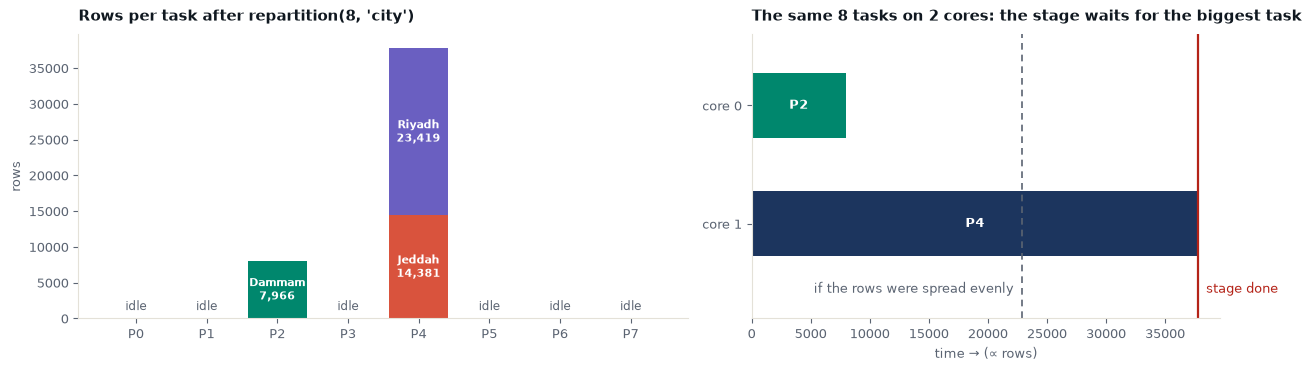

In [23]:
V.skew(skewed, cores=spark.sparkContext.defaultParallelism, n=8)

🔍 Three keys can keep at most three tasks busy. Here it's worse: Jeddah and Riyadh hash to the **same** partition,
so one task holds most of the orders while six tasks get nothing. The job finishes when that task finishes, and more
executors don't help: one partition is still one task.

Fixes: **AQE** (on by default) splits oversized partitions in sort-merge joins at run time; **salting** spreads one
key over several tasks; or pick a better key. Lab 3.2 measures skew on National Day and salts it.

In [24]:
print("AQE:", spark.conf.get("spark.sql.adaptive.enabled"),
      "| skew-join handling:", spark.conf.get("spark.sql.adaptive.skewJoin.enabled"))

AQE: true | skew-join handling: true


## 7 · Writing: one file per task

Executors write in parallel, so every task writes its own file. The number of files is the number of tasks in the
last stage, not something you choose directly. Here we spread `big_baskets` over 6 partitions before writing.

files written: 6


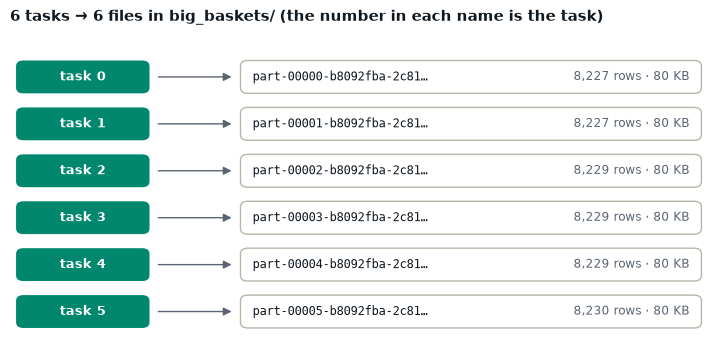

In [25]:
out = LAKE / "big_baskets"
big_baskets.repartition(6).write.mode("overwrite").parquet(out.as_posix())
print("files written:", U.count_files(out))
V.files(out)

🔍 With `partitionBy("day")`, each task writes one file **per folder it has rows for**: 1,000 tasks × 365 days =
365,000 small files. Lab 3.2 counts this and fixes it.

In [26]:
spark.stop()

## 8 · Summary

| | |
|---|---|
| **It does** | DataFrame and SQL transformations over many machines · reads and writes Parquet, Iceberg and Delta tables · batch and streaming (Structured Streaming) · Python, SQL, Scala and Java on one engine |
| **It doesn't** | pay off on data one machine handles (start-up, shuffles and a cluster to run) · store tables itself (a table format does: `df.writeTo("cat.db.orders").append()`) · schedule its jobs (Dagster, Day 4) |
| **In this course** | Lab 3.2: one metric three ways, partition pruning, broadcast timing, salting, small files |
| **As a service** | Databricks, AWS EMR and Glue, Google Dataproc, Microsoft Fabric, Azure Synapse: Spark with the cluster run for you |

**Cheat sheet**

| Code | Means |
|---|---|
| `spark.read.parquet(path)` | a DataFrame over Parquet files or a folder of them |
| `filter`, `withColumn`, `select` / `groupBy`, `distinct`, `join` | narrow (no data moves) / wide (a shuffle, a new stage) |
| `count`, `show`, `collect`, `toPandas`, `write` | actions: run the plan as jobs |
| `df.explain()` | the physical plan; read it bottom-up; `Exchange` = a shuffle |
| `df.rdd.getNumPartitions()`, `F.spark_partition_id()` | how many partitions / which one a row is in |
| `spark.sql.files.maxPartitionBytes` | the input split size: bigger splits, fewer tasks |
| `spark.sql.shuffle.partitions` | the number of partitions after a shuffle (default 200) |
| `F.broadcast(df)`, `df.hint("merge")` | force a broadcast join / a sort-merge join |
| `df.repartition(n, "col")` | shuffle into `n` partitions by a key |
| `df.write.partitionBy("col").parquet(path)` | one folder per value; one file per task per folder |
| `spark.sql.adaptive.enabled` | AQE: merges small shuffle partitions and splits skewed join partitions at run time |

## Checkpoint

1. A 40 GB daily job runs in DuckDB in 6 minutes. Should it move to Spark? What would change your answer?
2. Name two narrow and two wide operations. Why does a wide one start a new stage, and what does it cost?
3. A stage's 200 tasks finish in 30 s, but one runs for 40 minutes. What is the likely cause, and two fixes?
4. Why did 6 partitions write 6 files, and what happens with `partitionBy("day")` over a year?

Next: [Lab 3.2 · Spark](../D3_2_spark.ipynb). Docs:
[PySpark](https://spark.apache.org/docs/latest/api/python/index.html) ·
[performance tuning and AQE](https://spark.apache.org/docs/latest/sql-performance-tuning.html) ·
[the Spark UI](https://spark.apache.org/docs/latest/web-ui.html).

**What you built:** a small Parquet lake in `artifacts/tools_spark/`: `orders` in daily folders, three tables, and
`big_baskets` in six files.